## Week6-Chest X-Ray Images (Pneumonia)
**Name: Muhammad Bilal**

**Reg no: 04102313002**

## Part 0: The Configuration Cell 

In [1]:
DATA_ROOT = '/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray'
TRAIN_DIR = f'{DATA_ROOT}/train'
TEST_DIR = f'{DATA_ROOT}/test'
GRAYSCALE = True
IMG_SIZE = 224
BACKBONE = 'resnet18'
GROUP_PATTERN = r'(person\d+|IM-\d+|NORMAL2-IM-\d+)'
POSITIVE = 'PNEUMONIA'
TARGET_RECALL = 0.95

In [2]:
import os
import re
import time
import copy
import hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


# Part 1: Index and Audit Your Dataset


In [3]:
def index_folder(folder):
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls, 'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN and len(df) > 0:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None

classes = sorted(train_df['label'].unique())
counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max/min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')

label
NORMAL       1341
PNEUMONIA    3875
Imbalance ratio (max/min): 2.9
Images per group: 1.83


# Part 2: Leakage Audit (Duplicates and Group Split)

In [4]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

all_df = pd.concat([train_df.assign(split='train'), test_df.assign(split='test')]) if TEST_DIR else train_df
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))

sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'], train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)

if not TEST_DIR:
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train: {len(tr_df)} | val: {len(va_df)} | test: {len(test_df)}')
print('Groups shared by train and val:', len(shared))

Exact duplicate files: 62
train: 4354 | val: 862 | test: 624
Groups shared by train and val: 0


# Part 3: Transforms and Imbalance Handling

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []
train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)

n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)
print(dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)

val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

{'NORMAL': np.float64(1.935), 'PNEUMONIA': np.float64(0.674)}


# Part 4: Build, Train, Fine-tune; Select by Macro-F1

In [6]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, lastm = m, m.fc, m.layer4
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, lastm

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:', sum(p.numel() for p in model.parameters() if p.requires_grad))

def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} ({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
fit(model, head.parameters(), epochs=2, lr=1e-3)

print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
            {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 253MB/s]


resnet18 trainable: 1026
Phase 1: head only
epoch 1: val macro-F1 0.847 (73s)
epoch 2: val macro-F1 0.881 (72s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.947 (72s)
epoch 2: val macro-F1 0.941 (72s)
epoch 3: val macro-F1 0.919 (72s)


0.9466290588882773

# Part 5: Test Once; Threshold for Target Recall

              precision    recall  f1-score   support

      NORMAL      0.970     0.829     0.894       234
   PNEUMONIA      0.906     0.985     0.943       390

    accuracy                          0.926       624
   macro avg      0.938     0.907     0.919       624
weighted avg      0.930     0.926     0.925       624

Macro-F1: 0.919


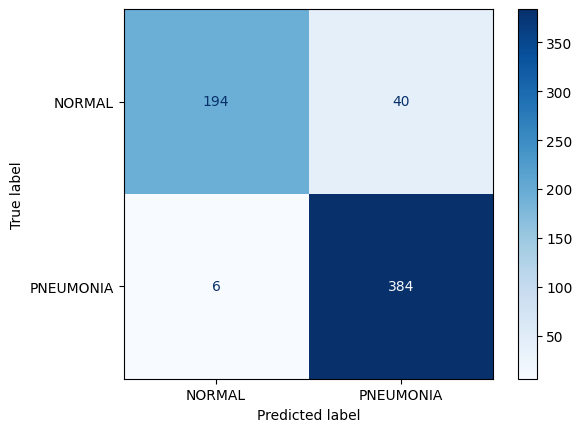

Threshold chosen on VALIDATION for recall >= 0.95: 0.355
Test AUC 0.979
Sensitivity 0.992 | Specificity 0.803 | PPV 0.894


In [7]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=classes).plot(cmap='Blues')
plt.show()

if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: {t:.3f}')
    
    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp/(tp+fn):.3f} | Specificity {tn/(tn+fp):.3f} | PPV {tp/max(tp+fp, 1):.3f}')

# Part 6: Grad-CAM Shortcut Check

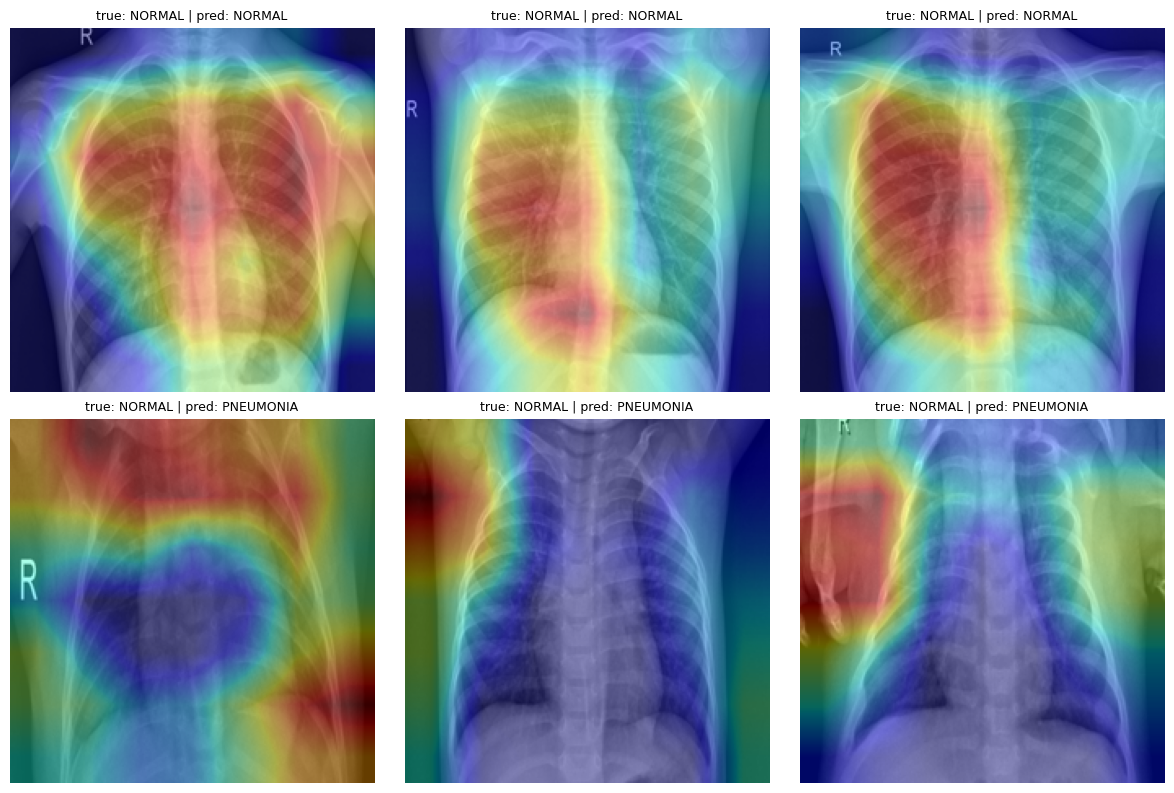

In [8]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()
        cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True

cam = GradCAM(model, last_block)
wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true: {classes[y]} | pred: {classes[c]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

# Part 7: Save Model Weights

In [9]:
torch.save({
    'state_dict': model.state_dict(),
    'classes': classes,
    'backbone': BACKBONE,
    'img_size': IMG_SIZE,
    'grayscale': GRAYSCALE
}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt
